# Week 6: Applied Computer Vision in My Own Domain — Crop Disease Classification
**Project 2: Deep Learning Applications** | Introduction to Applied AI | Department of Electronics
**Author:** Muhammad Raheel Ijaz

**Problem:** recognise the crop and its disease (or "healthy") from a photo of a single leaf — 38 classes.
**Who benefits:** farmers and agricultural extension workers, who could spot a disease early from a phone photo and treat it before it spreads.
**Dataset:** PlantVillage (Hughes & Salathé), Kaggle copy `abdallahalidev/plantvillage-dataset`, `color/` folder, licence CC BY-NC-SA 4.0.
**Backbone:** ResNet-18 pretrained on ImageNet, two-phase transfer learning (same pipeline as Week 5).
**Where it runs:** locally in Jupyter (no Kaggle). Works on CPU; much faster with an NVIDIA GPU.

### What I changed compared with the lab template (and why)
| Change | Reason |
|---|---|
| Paths are local Windows/pathlib paths, model/figures saved in `models/` and `images/` | No Kaggle; all files stay in the project folder |
| `SUBSAMPLE_FRAC` / `MIN_PER_CLASS` knobs | 54k images x 5 epochs is too slow on a CPU; the full audit in Part 1 still uses every image |
| `NUM_WORKERS = 0` | DataLoader workers crash or hang in Jupyter on Windows |
| `TEST_DIR = None` | PlantVillage has no test folder, so the code carves a *grouped* test set (lab design) |
| `GROUP_PATTERN = None` + **similarity groups** | PlantVillage file names carry no leaf id (checked in Part 1), so I build groups from near-duplicate clusters of the images themselves |
| Distance = RMS of the standardised 32x32 fingerprint (matrix form) | Same idea as the lab's mean-absolute difference but fast enough for thousands of images |
| Augmentation: flips added, no hue/saturation jitter | A leaf has no canonical orientation; disease colour must not be altered |
| Healthy-vs-diseased binary view (Part 5.2) | The lab's threshold / sensitivity / specificity / PPV section is for binary tasks; this gives a meaningful screening question for a 38-class problem |
| Extra Grad-CAM checks: border-attention share and a corner-pixels-only baseline | A measurable way to test the background shortcut suspected in the literature |

## Part 0: Configuration cell
This is the only cell to edit. Everything below reads from it.

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = 'data/plantvillage dataset/color'   # relative to the notebook folder (auto-checked below)
TRAIN_DIR = DATA_ROOT                           # folder with one subfolder per class
TEST_DIR = None                                 # PlantVillage has no test set -> grouped test set is carved
GRAYSCALE = False                               # leaf photos: colour carries the symptom
IMG_SIZE = 224
BACKBONE = 'resnet18'                           # or 'resnet50', 'efficientnet_b0'
GROUP_PATTERN = None                            # file names hold no leaf id -> similarity groups (see Part 2)
POSITIVE = 'DISEASED'                           # binary view: diseased leaf vs healthy leaf
TARGET_RECALL = 0.95                            # recall we must reach for diseased leaves
# ---- extra knobs I added (not in the lab template) ----
SUBSAMPLE_FRAC = 0.08     # fraction of images used for training/eval. 1.0 = all (use only with a GPU)
MIN_PER_CLASS = 30        # every class keeps at least this many images after subsampling
NUM_WORKERS = 0           # keep 0 on Windows + Jupyter
NEAR_DUP_THR = 0.10       # RMS fingerprint distance (std units) below which two images are near-duplicates
PREVALENCE_REAL = 0.10    # ASSUMPTION: share of photographed leaves that are really diseased in the field
# ======================================================================

In [2]:
import os
import re
import json
import time
import copy
import hashlib
import warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)
warnings.filterwarnings('ignore', category=UserWarning)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

PROJECT = Path.cwd()                       # the notebook lives in the project folder
IMAGES = PROJECT / 'images'
MODELS = PROJECT / 'models'
IMAGES.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(IMAGES / name, dpi=150, bbox_inches='tight')
R = {}                                     # results collected for the README / LinkedIn
print('Project folder:', PROJECT)

Device: cpu
Project folder: D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications


In [3]:
# Check that the dataset folder is where the config says (and try to find it if not)
def n_class_dirs(p):
    return sum(1 for d in p.iterdir() if d.is_dir()) if p.is_dir() else 0
data_root = Path(TRAIN_DIR)
if not data_root.is_absolute():
    data_root = PROJECT / data_root
if n_class_dirs(data_root) < 2:
    print('Not found at', data_root, '- searching inside data/ ...')
    cands = [d for d in (PROJECT / 'data').rglob('*')
             if d.is_dir() and d.name.lower() == 'color' and n_class_dirs(d) >= 30]
    if len(cands) == 1:
        data_root = cands[0]
    else:
        raise SystemExit(f'Could not locate the PlantVillage "color" folder automatically '
                         f'({len(cands)} candidates). Set DATA_ROOT in the config cell.')
TRAIN_DIR = str(data_root)
print('Using dataset folder:', TRAIN_DIR)
print('Number of class folders:', n_class_dirs(data_root))

Using dataset folder: D:\Documents-D\7th Semester\Intro to AI\Project-2\Deep Learning Applications\data\plantvillage dataset\color
Number of class folders: 38


## Part 1: Index and audit the dataset
### Task 1.1: One row per image

label
Apple___Apple_scab                                     629
Apple___Black_rot                                      621
Apple___Cedar_apple_rust                               275
Apple___healthy                                       1645
Blueberry___healthy                                   1502
Cherry_(including_sour)___Powdery_mildew              1052
Cherry_(including_sour)___healthy                      854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
Corn_(maize)___Common_rust_                           1192
Corn_(maize)___Northern_Leaf_Blight                    985
Corn_(maize)___healthy                                1162
Grape___Black_rot                                     1180
Grape___Esca_(Black_Measles)                          1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)            1076
Grape___healthy                                        423
Orange___Haunglongbing_(Citrus_greening)              5507
Peach___Bacterial_spot                            

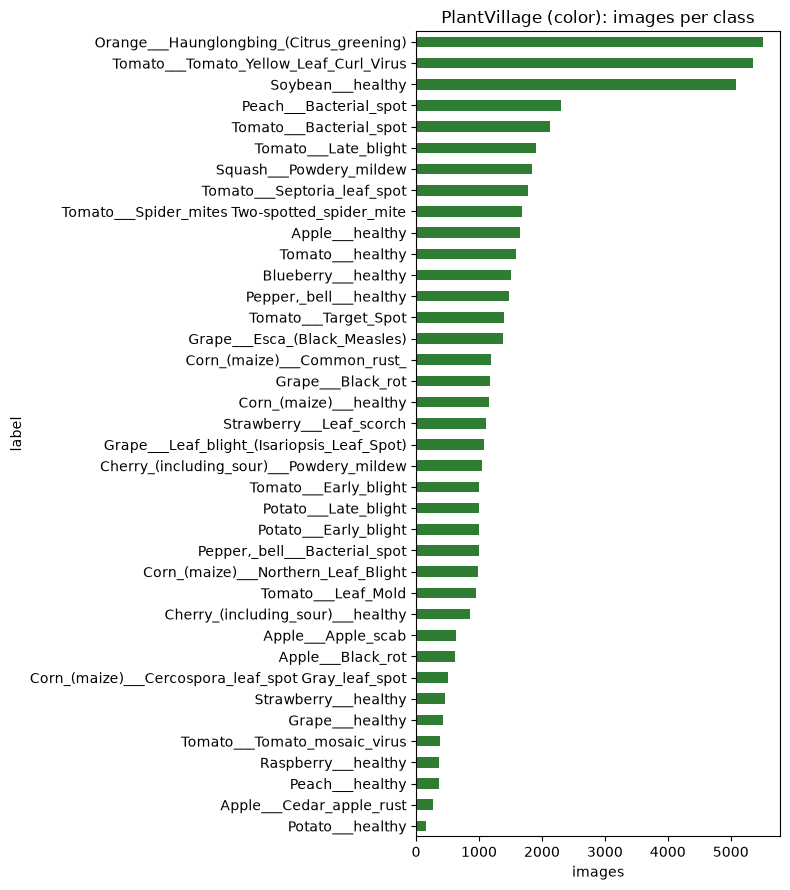

In [4]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df
full_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(full_df['label'].unique())
counts = full_df['label'].value_counts().reindex(classes)
print(counts.to_string())
imb_full = counts.max() / counts.min()
print(f'\nTotal images: {len(full_df)} | classes: {len(classes)}')
print(f'Imbalance ratio (max / min): {imb_full:.1f}')
print(f'Images per group (file-name groups): {len(full_df) / full_df.group.nunique():.2f}')
print('\nFirst file names (is there a leaf / plant id in them?):')
print(full_df['file'].head(6).to_string(index=False))
R.update(n_full=int(len(full_df)), n_classes=len(classes), imb_full=float(imb_full),
         biggest=(counts.idxmax(), int(counts.max())), smallest=(counts.idxmin(), int(counts.min())))

fig, ax = plt.subplots(figsize=(8, 9))
counts.sort_values().plot.barh(ax=ax, color='#2e7d32')
ax.set_xlabel('images'); ax.set_title('PlantVillage (color): images per class')
plt.tight_layout(); savefig('w6_class_counts.png'); plt.show()

### Task 1.2: What do the images look like?

         w      h
min  256.0  256.0
50%  256.0  256.0
max  256.0  256.0
Colour modes: {'RGB': 300}


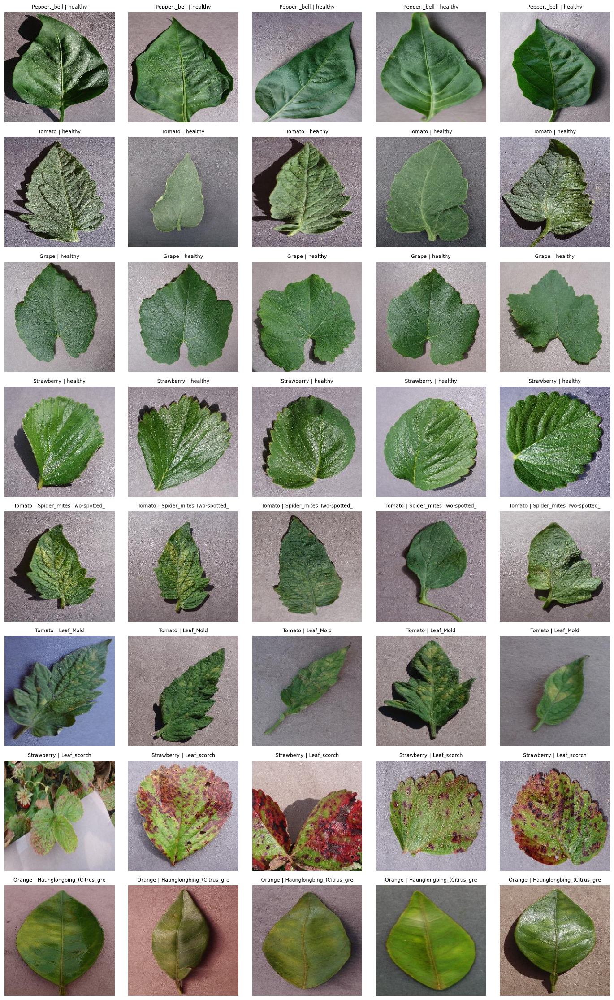

Healthy classes: 12 | diseased classes: 26


In [5]:
sample = full_df.sample(min(300, len(full_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())
R['img_size'] = (int(info.w.median()), int(info.h.median()))
R['modes'] = info['mode'].value_counts().to_dict()

healthy_cls = [c for c in classes if c.lower().endswith('healthy')]
disease_cls = [c for c in classes if c not in healthy_cls]
rng = np.random.RandomState(0)
show = (list(rng.choice(healthy_cls, min(4, len(healthy_cls)), replace=False)) +
        list(rng.choice(disease_cls, min(4, len(disease_cls)), replace=False)))
fig, axes = plt.subplots(len(show), 5, figsize=(14, 2.8 * len(show)))
axes = np.atleast_2d(axes)
for r, c in enumerate(show):
    sub = full_df[full_df.label == c]['path']
    paths = sub.sample(min(5, len(sub)), random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c.replace('___', ' | ')[:34], fontsize=8)
        ax.axis('off')
plt.tight_layout(); savefig('w6_sample_grid.png'); plt.show()
print('Healthy classes:', len(healthy_cls), '| diseased classes:', len(disease_cls))

### ✍️ Write it — Part 1
- **Class counts and imbalance ratio:** the full PlantVillage `color` folder has 54,304 images in 38 classes (12 healthy and 26 diseased classes). The largest class is `Orange___Haunglongbing_(Citrus_greening)` with 5,507 images and the smallest is `Potato___healthy` with 152 images, so the imbalance ratio is 5,507 / 152 = **36.2**. Three classes (Orange, Tomato Yellow Leaf Curl Virus with 5,357, and Soybean healthy with 5,090) hold about 29% of all images. For CPU training I use a stratified working set of 4,372 images (30 to 441 per class, imbalance ratio 14.7).
- **Colour and size:** all 300 sampled images are RGB colour photos and all are 256 x 256 px (minimum, median and maximum are identical). I keep colour (`GRAYSCALE = False`) because the colour of a lesion is the symptom.
- **First shortcut suspect:** the background and lighting. Every leaf lies on a grey table, but the shade differs between classes: Orange images have pink, brown or grey backgrounds, some Tomato Leaf Mold images have a blue one, Tomato healthy has a dark grey background with hard shadows, Grape healthy is light grey, and one Strawberry Leaf scorch image is a photo with other plants around the leaf. The background is not the disease, but if each class was photographed on a different table or day, the model could learn the background instead of the lesions. [Noyan 2022](https://arxiv.org/abs/2206.04374) reported exactly this kind of leak in PlantVillage.

### Task 1.3 (my addition): subsample for CPU training
The audit above used **all** images. From here on I work with a stratified subsample (`SUBSAMPLE_FRAC`, at least `MIN_PER_CLASS` per class), which keeps the class imbalance pattern but makes CPU training feasible.

In [6]:
def subsample(df, frac, min_per_class, seed=42):
    if frac >= 1:
        return df.reset_index(drop=True)
    parts = []
    for c, g in df.groupby('label'):
        k = min(len(g), max(int(round(len(g) * frac)), min_per_class))
        parts.append(g.sample(k, random_state=seed))
    return pd.concat(parts).sort_values('path').reset_index(drop=True)
train_df = subsample(full_df, SUBSAMPLE_FRAC, MIN_PER_CLASS)
c_sub = train_df['label'].value_counts().reindex(classes)
imb_sub = c_sub.max() / c_sub.min()
print(f'Working set: {len(train_df)} images (of {len(full_df)}) | imbalance ratio {imb_sub:.1f}')
print(c_sub.describe().round(0).to_string())
R.update(n_work=int(len(train_df)), imb_sub=float(imb_sub))

Working set: 4372 images (of 54304) | imbalance ratio 14.7
count     38.0
mean     115.0
std      101.0
min       30.0
25%       54.0
50%       88.0
75%      131.0
max      441.0


## Part 2: Leakage audit
### Task 2.1: Exact and near-duplicates
MD5 finds byte-identical files (checked on the **whole** dataset). The fingerprint (a standardised 32 x 32 grayscale thumbnail) finds the same image resized, recompressed or brightened (checked on the working set).

In [7]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

t0 = time.time()
full_df['md5'] = [md5(p) for p in full_df['path']]
exact = full_df[full_df.duplicated('md5', keep=False)].sort_values('md5')
sets = exact.groupby('md5')
conflict = int((sets['label'].nunique() > 1).sum()) if len(exact) else 0
print(f'MD5 on {len(full_df)} files took {time.time() - t0:.0f}s')
print('Exact duplicate files (whole dataset):', len(exact), 'in', exact.md5.nunique(), 'sets')
print('Duplicate sets whose copies carry DIFFERENT labels:', conflict)
if len(exact):
    print(exact[['label', 'file']].head(6).to_string(index=False))
R.update(exact_files=int(len(exact)), exact_sets=int(exact.md5.nunique()), exact_conflict=conflict)
train_df = train_df.merge(full_df[['path', 'md5']], on='path', how='left')

MD5 on 54304 files took 14s
Exact duplicate files (whole dataset): 42 in 21 sets
Duplicate sets whose copies carry DIFFERENT labels: 0
               label                                                       file
Tomato___Late_blight 5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG
Tomato___Late_blight e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG
     Apple___healthy      14896dc0-688d-456f-b5ec-a037695b0193___RS_HL 6268.JPG
     Apple___healthy      c21cf428-bfc3-4710-b5d2-69d1c0e94748___RS_HL 6268.JPG
Tomato___Late_blight 2c47b891-3c97-48f1-a2cc-5aa53d3a1148___GHLB2 Leaf 9011.JPG
Tomato___Late_blight 1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG


Fingerprints (4372, 1024) in 8s

Images whose nearest neighbour (inside the working set) is closer than each threshold:
  distance < 0.02: 0 images
  distance < 0.05: 0 images
  distance < 0.10: 0 images
  distance < 0.20: 0 images
  distance < 0.30: 2 images

Flagged as near-duplicates at 0.1: 0 of 4372
Closest distances: [0.249 0.249 0.311 0.311 0.379]


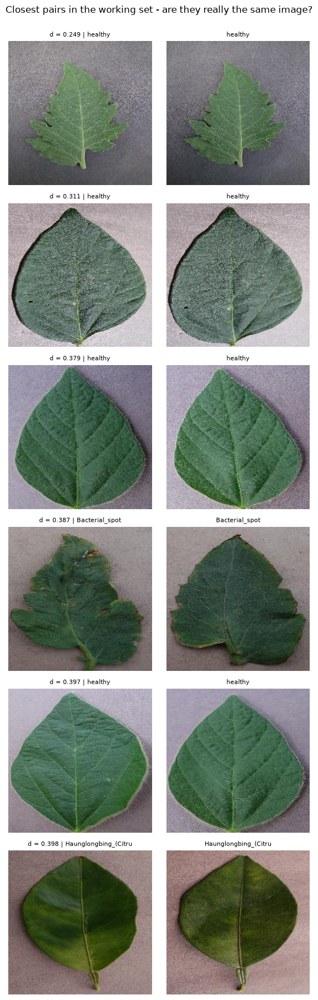

In [8]:
t0 = time.time()
FPR = np.stack([fingerprint(p) for p in train_df['path']]).astype(np.float32)
print(f'Fingerprints {FPR.shape} in {time.time() - t0:.0f}s')

def nn_dist(A, B, same=False, chunk=1024):
    """For each row of A: RMS distance to its nearest row of B (and which row)."""
    A_t, B_t = torch.from_numpy(A), torch.from_numpy(B)
    bb = (B_t ** 2).sum(1)
    n = A.shape[1]
    dmin, imin = [], []
    for s in range(0, len(A_t), chunk):
        a = A_t[s:s + chunk]
        d2 = (a ** 2).sum(1, keepdim=True) + bb[None, :] - 2 * a @ B_t.T
        if same:
            r = torch.arange(len(a))
            d2[r, r + s] = float('inf')
        m, idx = d2.min(1)
        dmin.append((m.clamp(min=0) / n).sqrt()); imin.append(idx)
    return torch.cat(dmin).numpy(), torch.cat(imin).numpy()

def near_pairs(A, thr, chunk=1024):
    """All (i, j), i != j, with RMS distance < thr."""
    A_t = torch.from_numpy(A)
    aa = (A_t ** 2).sum(1)
    n = A.shape[1]
    I, J = [], []
    for s in range(0, len(A_t), chunk):
        a = A_t[s:s + chunk]
        d2 = (aa[s:s + chunk, None] + aa[None, :] - 2 * a @ A_t.T).clamp(min=0) / n
        ii, jj = torch.where(d2 < thr ** 2)
        ii = ii + s
        keep = ii != jj
        I.append(ii[keep]); J.append(jj[keep])
    return torch.cat(I).numpy().astype(np.int64), torch.cat(J).numpy().astype(np.int64)

d_self, nn_self = nn_dist(FPR, FPR, same=True)
print('\nImages whose nearest neighbour (inside the working set) is closer than each threshold:')
for thr in [0.02, 0.05, 0.10, 0.20, 0.30]:
    print(f'  distance < {thr:.2f}: {(d_self < thr).sum()} images')
n_near = int((d_self < NEAR_DUP_THR).sum())
print(f'\nFlagged as near-duplicates at {NEAR_DUP_THR}: {n_near} of {len(train_df)}')
print('Closest distances:', np.sort(d_self)[:5].round(3))
R['near_inside'] = n_near

# Look at the closest pairs BEFORE deciding anything
seen, pairs, dists = set(), [], []
for i in np.argsort(d_self):
    j = int(nn_self[i])
    if (j, int(i)) in seen:
        continue
    seen.add((int(i), j)); pairs.append((int(i), j)); dists.append(float(d_self[i]))
    if len(pairs) == 6:
        break
fig, axes = plt.subplots(len(pairs), 2, figsize=(6, 3 * len(pairs)))
axes = np.atleast_2d(axes)
for r, ((i, j), d) in enumerate(zip(pairs, dists)):
    for ax, k in zip(axes[r], (i, j)):
        ax.imshow(Image.open(train_df.path.iloc[k]).convert('RGB')); ax.axis('off')
    axes[r, 0].set_title(f'd = {d:.3f} | {train_df.label.iloc[i].split("___")[-1][:20]}', fontsize=8)
    axes[r, 1].set_title(train_df.label.iloc[j].split('___')[-1][:20], fontsize=8)
plt.suptitle('Closest pairs in the working set - are they really the same image?', y=1.0)
plt.tight_layout(); savefig('w6_closest_pairs.png'); plt.show()

**Before deleting or merging anything:** look at the pairs above. If a pair is the same leaf (or a flip / crop / re-save of it) it is a real near-duplicate; if they are only two similar-looking leaves, tighten `NEAR_DUP_THR` (e.g. 0.05). The next step does not delete anything: it puts near-duplicates in the **same group** so they can never be split across train/val/test.

### Task 2.2: Split by group (similarity groups)

In [9]:
# (a) What a RANDOM split would have leaked (measured, not guessed)
r_tr, r_va = train_test_split(np.arange(len(train_df)), test_size=1 / 6,
                              random_state=42, stratify=train_df['label'])
d_rand, _ = nn_dist(FPR[r_va], FPR[r_tr])
print(f'RANDOM split: {len(r_tr)} train / {len(r_va)} val')
for thr in [0.05, 0.10, 0.20]:
    print(f'  val images with a train neighbour closer than {thr:.2f}: {(d_rand < thr).sum()}')
R['rand_leak'] = int((d_rand < NEAR_DUP_THR).sum()); R['rand_val'] = int(len(r_va))

# (b) Build groups: every connected cluster of near-duplicates becomes ONE group
n = len(train_df)
I, J = near_pairs(FPR, NEAR_DUP_THR)
pi, pj = [], []
for _, idx in train_df.groupby('group').indices.items():     # same file-name group (if GROUP_PATTERN is set)
    pi += list(idx[:-1]); pj += list(idx[1:])
I = np.concatenate([I, np.array(pi, dtype=np.int64)])
J = np.concatenate([J, np.array(pj, dtype=np.int64)])
n_comp, comp = connected_components(coo_matrix((np.ones(len(I)), (I, J)), shape=(n, n)), directed=False)
train_df['group'] = ['g' + str(c) for c in comp]
gsize = train_df.groupby('group').size()
print(f'\nGroups: {n_comp} for {n} images -> {n / n_comp:.2f} images per group')
print(f'Groups with more than one image: {(gsize > 1).sum()} | largest group: {gsize.max()} images')
R.update(n_groups=int(n_comp), per_group=float(n / n_comp), largest_group=int(gsize.max()))
if gsize.max() > 0.05 * n:
    print('WARNING: one group holds >5% of the data. Lower NEAR_DUP_THR (e.g. 0.05) and re-run from Task 2.1.')

RANDOM split: 3643 train / 729 val
  val images with a train neighbour closer than 0.05: 0
  val images with a train neighbour closer than 0.10: 0
  val images with a train neighbour closer than 0.20: 0

Groups: 4372 for 4372 images -> 1.00 images per group
Groups with more than one image: 0 | largest group: 1 images


In [10]:
# Validation (and test) split BY GROUP: no group appears on two sides
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
all_idx = np.arange(len(train_df))
tr_idx, va_idx = next(sgkf.split(all_idx, train_df['label'], train_df['group']))
if not TEST_DIR:                                  # carve a grouped test set
    sub = train_df.iloc[tr_idx]
    t2, te2 = next(sgkf.split(sub, sub['label'], sub['group']))
    te_idx, tr_idx = tr_idx[te2], tr_idx[t2]
    test_df = train_df.iloc[te_idx].reset_index(drop=True)
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
shared = set(tr_df.group) & set(va_df.group)
shared_te = (set(tr_df.group) | set(va_df.group)) & set(test_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))            # must be 0
print('Groups shared by test and (train or val):', len(shared_te))   # must be 0
print('\nVal images per class (smallest 5):')
print(va_df['label'].value_counts().sort_values().head(5).to_string())
R.update(n_train=len(tr_df), n_val=len(va_df), n_test=len(test_df), shared=len(shared) + len(shared_te))

# Cross-split leakage check with the fingerprints and MD5
if not TEST_DIR:
    d_va, _ = nn_dist(FPR[va_idx], FPR[tr_idx])
    d_te, _ = nn_dist(FPR[te_idx], FPR[tr_idx])
    for name, d in [('val', d_va), ('test', d_te)]:
        print(f'{name}: near-duplicate in train  <{NEAR_DUP_THR}: {(d < NEAR_DUP_THR).sum()} of {len(d)}'
              f'   |  <0.20: {(d < 0.20).sum()}')
    R['near_val_train'] = int((d_va < NEAR_DUP_THR).sum()); R['near_test_train'] = int((d_te < NEAR_DUP_THR).sum())
    ex_vt = len(set(va_df.md5) & set(tr_df.md5)); ex_tt = len(set(test_df.md5) & set(tr_df.md5))
    print('Exact (MD5) overlaps: val-train', ex_vt, '| test-train', ex_tt)
    R['exact_cross'] = ex_vt + ex_tt

train 3035 | val 729 | test 608
Groups shared by train and val: 0
Groups shared by test and (train or val): 0

Val images per class (smallest 5):
label
Raspberry___healthy             5
Potato___healthy                5
Peach___healthy                 5
Tomato___Tomato_mosaic_virus    5
Apple___Cedar_apple_rust        5
val: near-duplicate in train  <0.1: 0 of 729   |  <0.20: 0
test: near-duplicate in train  <0.1: 0 of 608   |  <0.20: 0
Exact (MD5) overlaps: val-train 0 | test-train 0


### ✍️ Write it — Part 2
- **Exact duplicates:** 42 files in 21 sets in the whole dataset (MD5 on all 54,304 files). No set has conflicting labels. The copies I looked at are the same photo stored twice in the same class (for example `Tomato___Late_blight` source image 8999 and `Apple___healthy` source image 6268). Between splits: none. The MD5 overlap is 0 between validation and train and 0 between test and train.
- **Near-duplicates:** in the 4,372-image working set 0 images are closer than 0.20, only 2 are closer than 0.30, and the closest distance is 0.249. At my threshold of 0.10 nothing is flagged, and 0 of 729 validation and 0 of 608 test images have a near-duplicate in train. I looked at the closest pairs: the ones at 0.25 to 0.40 (tomato, soybean, citrus) are clearly the same leaf photographed a second time in a slightly different pose, so "sibling" shots exist but are not close enough for the 0.10 threshold. What I did: I kept the threshold at 0.10 and removed nothing. My working set holds only 8% of the images, so the sibling of most leaves is not in it, and I expect grouping at a looser threshold to change very little.
- **Images per group:** 1.00 (4,372 groups for 4,372 images, largest group 1 image). The file names are only a random ID plus a source number, with no leaf id, so my groups come from image similarity; because nothing was similar enough, every image is its own group and the split behaves like a random split.
- **Random vs group split:** a random split of my working set would have put 0 of 729 validation images next to a near-duplicate in train at 0.10, so this check shows no measurable gain from grouping. Sibling shots of the same leaf would still land on both sides of the split, so the model could recognise a leaf it has already seen and the test score would be optimistic; with my split the same count is 0 and the shared groups are 0, but I cannot rule out this leaf-level leakage.

## Part 3: Transforms and imbalance
### Task 3.1: Datasets and transforms
Augmentation choices for leaves: random crop (scale 0.8 to 1), rotation ±10°, mild brightness/contrast (±0.15), **plus horizontal and vertical flips** (a leaf photo has no canonical orientation). No hue or saturation jitter: the colour of a lesion *is* the evidence.

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []
train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]
train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(len(train_ds), len(val_ds), len(test_ds))

3035 729 608


### Task 3.2: Class weights or balanced sampling

In [12]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('Smallest / largest class weight:', class_w.min().round(3), '/', class_w.max().round(3))
print(pd.Series(class_w.round(3), index=classes).sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_string())
k_min, k_max = int(np.argmin(n_c)), int(np.argmax(n_c))
for k in (k_min, k_max):
    print(f'\n{classes[k]}: n_c = {n_c[k]}  ->  w = N / (K * n_c) = {len(train_ds)} / ({len(classes)} * {n_c[k]}) = {class_w[k]:.3f}')
R.update(w_min=float(class_w.min()), w_max=float(class_w.max()),
         w_example=(classes[k_min], int(n_c[k_min]), float(class_w[k_min])))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

Smallest / largest class weight: 0.261 / 3.803
Orange___Haunglongbing_(Citrus_greening)    0.261
Tomato___Tomato_Yellow_Leaf_Curl_Virus      0.269
Soybean___healthy                           0.283
Apple___Cedar_apple_rust                    3.803
Potato___healthy                            3.803
Tomato___Tomato_mosaic_virus                3.803

Apple___Cedar_apple_rust: n_c = 21  ->  w = N / (K * n_c) = 3035 / (38 * 21) = 3.803

Orange___Haunglongbing_(Citrus_greening): n_c = 306  ->  w = N / (K * n_c) = 3035 / (38 * 306) = 0.261


In [13]:
USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=NUM_WORKERS)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=NUM_WORKERS)
val_dl = DataLoader(val_ds, 64, num_workers=NUM_WORKERS)
test_dl = DataLoader(test_ds, 64, num_workers=NUM_WORKERS)
R['imbalance_method'] = 'balanced sampler' if USE_SAMPLER else 'class-weighted cross-entropy'
print('Imbalance handling:', R['imbalance_method'])

Imbalance handling: class-weighted cross-entropy


### ✍️ Write it — Part 3
- **Class weights:** the smallest weight is 0.261 (`Orange___Haunglongbing_(Citrus_greening)`, 306 training images) and the largest is 3.803 (for example `Apple___Cedar_apple_rust`, `Potato___healthy` and `Tomato___Tomato_mosaic_virus`, 21 training images each). Arithmetic for one class: N = 3,035, K = 38, n_c = 21 → w = 3,035 / (38 x 21) = 3,035 / 798 = 3.803 (matches the printed value: yes). For Orange: 3,035 / (38 x 306) = 3,035 / 11,628 = 0.261. A rare-class image therefore counts about 14.6 times as much as an Orange image in the loss.
- **Augmentations:** I kept the random crop (scale 0.8 to 1), the rotation of ±10° and the mild brightness/contrast jitter (±0.15), because they imitate small differences in framing and lighting. I added horizontal and vertical flips because a leaf has no fixed orientation. I did not use hue or saturation jitter, because yellowing, browning and spots are the evidence of disease and colour changes could turn one class into another.
- **Sampler (optional):** I did not run `USE_SAMPLER = True`; all results use the weighted cross-entropy loss.

## Part 4: Build and train
### Task 4.1: Backbone with a new head

In [14]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last
model, head, last_block = build_model(BACKBONE, len(classes))
n_head = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(BACKBONE, 'trainable:', n_head)
R['params_head'] = int(n_head)

resnet18 trainable: 19494


### Task 4.2: Two-phase training, selected by macro-F1

In [15]:
hist = []
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()
def fit(model, params, epochs, lr, phase):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro', zero_division=0)   # not accuracy
        acc = float((p.argmax(1) == y).mean())
        hist.append({'phase': phase, 'epoch': ep + 1, 'macro_f1': macro, 'acc': acc,
                     'sec': time.time() - t0})
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'phase {phase} epoch {ep + 1}: val macro-F1 {macro:.3f}  (acc {acc:.3f})  '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best
print('Phase 1: head only')
p1_best = fit(model, head.parameters(), epochs=2, lr=1e-3, phase=1)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
n_ft = sum(p.numel() for p in model.parameters() if p.requires_grad)
p2_best = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                      {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3, phase=2)
print(f'\nBest val macro-F1: phase 1 = {p1_best:.3f}, phase 2 = {p2_best:.3f}  (trainable params {n_head:,} -> {n_ft:,})')
R.update(p1_best=float(p1_best), p2_best=float(p2_best), params_ft=int(n_ft),
         sec_p1=float(np.mean([h['sec'] for h in hist if h['phase'] == 1])),
         sec_p2=float(np.mean([h['sec'] for h in hist if h['phase'] == 2])))

Phase 1: head only
phase 1 epoch 1: val macro-F1 0.583  (acc 0.658)  (568s)
phase 1 epoch 2: val macro-F1 0.786  (acc 0.818)  (529s)
Phase 2: fine-tune the last block
phase 2 epoch 1: val macro-F1 0.879  (acc 0.892)  (625s)
phase 2 epoch 2: val macro-F1 0.929  (acc 0.937)  (641s)
phase 2 epoch 3: val macro-F1 0.927  (acc 0.936)  (664s)

Best val macro-F1: phase 1 = 0.786, phase 2 = 0.929  (trainable params 19,494 -> 8,413,222)


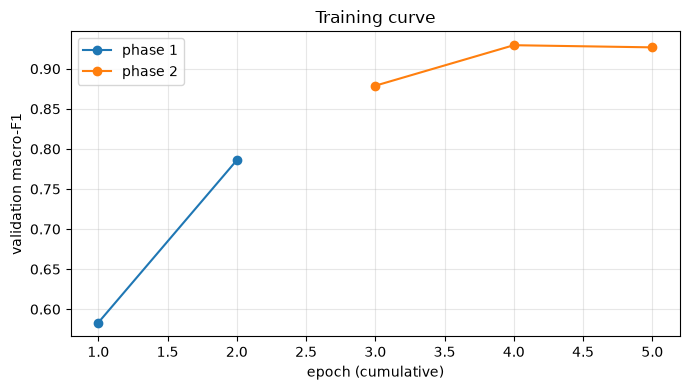

 phase  epoch  macro_f1   acc     sec  step
     1      1     0.583 0.658 567.578     1
     1      2     0.786 0.818 529.351     2
     2      1     0.879 0.892 624.953     3
     2      2     0.929 0.937 641.377     4
     2      3     0.927 0.936 664.463     5


In [16]:
h = pd.DataFrame(hist)
h['step'] = range(1, len(h) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for ph, g in h.groupby('phase'):
    ax.plot(g['step'], g['macro_f1'], marker='o', label=f'phase {ph}')
ax.set_xlabel('epoch (cumulative)'); ax.set_ylabel('validation macro-F1'); ax.set_title('Training curve')
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); savefig('w6_learning_curve.png'); plt.show()
print(h.round(3).to_string(index=False))

### ✍️ Write it — Part 4
- **Validation macro-F1:** 0.786 after phase 1 (head only, 19,494 trainable parameters) and 0.929 after phase 2 (layer4 + head, 8,413,222 trainable parameters). Fine-tuning helped by 14.3 points because the frozen ImageNet features are not specific to leaf lesions, and unfreezing layer4 lets the network adapt its high-level features to symptoms such as spots, mould and curling.
- **Time:** on my CPU a phase-1 epoch took about 530 to 570 s (roughly 9 minutes) and a phase-2 epoch about 625 to 665 s (roughly 11 minutes); the five epochs together took about 50 minutes. The curve shows phase 2 peaking at its second epoch (0.929) and then staying flat (0.927), so more fine-tuning would give little; with more time I would add about 2 to 3 more phase-2 epochs with a smaller learning rate and keep the best epoch by macro-F1, and run a third phase-1 epoch because that curve was still rising fast (0.583 to 0.786).
- **Why macro-F1 and not accuracy for choosing the best epoch:** accuracy is dominated by the big classes (Orange, Tomato Yellow Leaf Curl Virus and Soybean healthy are about 29% of the images), so a model could neglect small classes such as Potato healthy and still score well. Macro-F1 gives each of the 38 classes the same weight, so an epoch that fails on rare classes cannot win.

## Part 5: Test once, and set the threshold
### Task 5.1: Test-set report
The test set is used **once** here; everything later (threshold, Grad-CAM) reuses these predictions.

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      1.000     1.000     1.000         7
                                 Apple___Black_rot      1.000     1.000     1.000         7
                          Apple___Cedar_apple_rust      1.000     1.000     1.000         4
                                   Apple___healthy      0.950     1.000     0.974        19
                               Blueberry___healthy      1.000     1.000     1.000        16
          Cherry_(including_sour)___Powdery_mildew      1.000     1.000     1.000        12
                 Cherry_(including_sour)___healthy      0.900     1.000     0.947         9
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      1.000     0.833     0.909         6
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000        13
               Corn_(maize)___Northern_Leaf_Blight      0.917     1.000     0.9

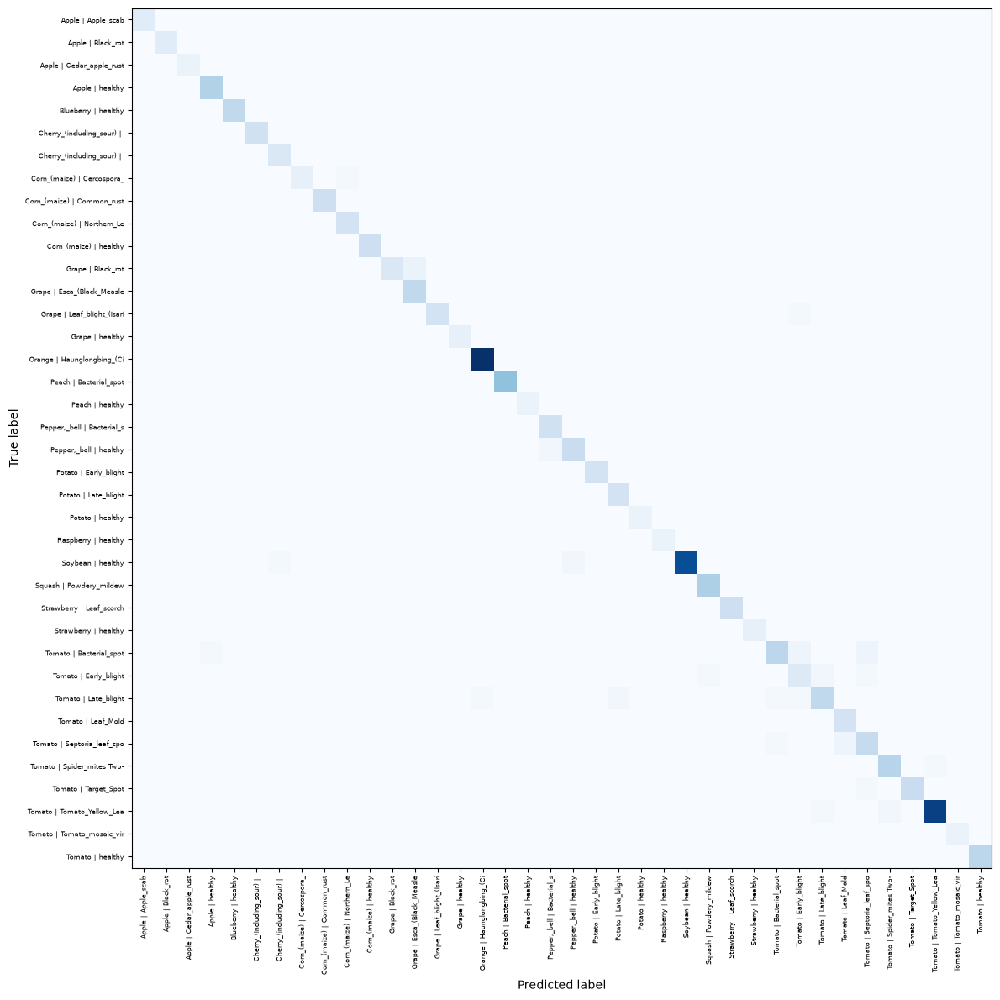

In [17]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
K = len(classes)
print(classification_report(y_test, pred, labels=list(range(K)), target_names=classes,
                            digits=3, zero_division=0))
macro_test = f1_score(y_test, pred, average='macro', zero_division=0)
acc_test = float((pred == y_test).mean())
print('Macro-F1:', round(macro_test, 3), '| accuracy:', round(acc_test, 3))

cm = confusion_matrix(y_test, pred, labels=list(range(K)))
support = cm.sum(1)
recall = np.divide(np.diag(cm), support, out=np.zeros(K), where=support > 0)
rec_df = pd.DataFrame({'class': classes, 'support': support, 'recall': recall.round(3)}).sort_values('recall')
print('\nWeakest classes by recall:')
print(rec_df.head(8).to_string(index=False))
off = cm.copy(); np.fill_diagonal(off, 0)
print('\nLargest confusions (true -> predicted : count):')
for flat in np.argsort(-off, axis=None)[:6]:
    i, j = np.unravel_index(flat, off.shape)
    if off[i, j] > 0:
        print(f'  {classes[i]} -> {classes[j]} : {off[i, j]}')
weakest = rec_df.iloc[0]
R.update(macro_test=float(macro_test), acc_test=acc_test, weakest=(weakest['class'], float(weakest['recall']), int(weakest['support'])))

fig, ax = plt.subplots(figsize=(13, 12))
ConfusionMatrixDisplay(cm, display_labels=[c.replace('___', ' | ')[:26] for c in classes]).plot(
    ax=ax, cmap='Blues', include_values=False, xticks_rotation=90, colorbar=False)
ax.tick_params(labelsize=6)
plt.tight_layout(); savefig('w6_confusion_matrix.png'); plt.show()

### Task 5.2: Threshold for a target recall — healthy vs diseased view
PlantVillage is a 38-class problem, so the binary threshold analysis is done on the question a farmer actually asks: **"is this leaf diseased?"**
Score = 1 − (sum of the probabilities of all `*healthy` classes). The threshold is chosen on **validation** and then applied once to the test predictions.

In [18]:
healthy_idx = [i for i, c in enumerate(classes) if c.lower().endswith('healthy')]
def p_dis(p):
    return 1 - p[:, healthy_idx].sum(1)
p_val, y_val = predict(model, val_dl)
yv = ~np.isin(y_val, healthy_idx)                       # True = diseased
fpr, tpr, thr = roc_curve(yv, p_dis(p_val))
t = thr[np.argmax(tpr >= TARGET_RECALL)]                # highest t reaching target
print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')
s = p_dis(p_test)
yt = ~np.isin(y_test, healthy_idx)
yp = s >= t
tp, fn = (yp & yt).sum(), (~yp & yt).sum()
tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
sens, spec, ppv_test = tp / (tp + fn), tn / (tn + fp), tp / max(tp + fp, 1)
prev_test = yt.mean()
auc = roc_auc_score(yt, s)
print(f'Test prevalence of diseased leaves: {prev_test:.3f}')
print(f'Test AUC {auc:.3f}')
print(f'Sensitivity {sens:.3f}   Specificity {spec:.3f}   PPV {ppv_test:.3f}')
print('Target recall reached on test:', bool(sens >= TARGET_RECALL))
print(f'TP {tp}  FN {fn}  TN {tn}  FP {fp}')

# PPV at a realistic prevalence (formula from the slides), working shown
def ppv_at(prev, se, sp):
    return se * prev / (se * prev + (1 - sp) * (1 - prev))
ppv_real = ppv_at(PREVALENCE_REAL, sens, spec)
print(f'\nPPV at test prevalence {prev_test:.3f}: {ppv_at(prev_test, sens, spec):.3f}  (matches direct count {ppv_test:.3f})')
print(f'PPV at realistic prevalence {PREVALENCE_REAL}:')
print(f'  PPV = Se*prev / (Se*prev + (1-Sp)*(1-prev))')
print(f'      = {sens:.3f}*{PREVALENCE_REAL} / ({sens:.3f}*{PREVALENCE_REAL} + {1 - spec:.3f}*{1 - PREVALENCE_REAL})')
print(f'      = {sens * PREVALENCE_REAL:.4f} / {sens * PREVALENCE_REAL + (1 - spec) * (1 - PREVALENCE_REAL):.4f} = {ppv_real:.3f}')
R.update(thr=float(t), sens=float(sens), spec=float(spec), ppv_test=float(ppv_test), prev_test=float(prev_test),
         ppv_real=float(ppv_real), auc=float(auc))

Threshold chosen on VALIDATION for recall >= 0.95: 0.639
Test prevalence of diseased leaves: 0.722
Test AUC 1.000
Sensitivity 0.995   Specificity 0.982   PPV 0.993
Target recall reached on test: True
TP 437  FN 2  TN 166  FP 3

PPV at test prevalence 0.722: 0.993  (matches direct count 0.993)
PPV at realistic prevalence 0.1:
  PPV = Se*prev / (Se*prev + (1-Sp)*(1-prev))
      = 0.995*0.1 / (0.995*0.1 + 0.018*0.9)
      = 0.0995 / 0.1155 = 0.862


**Hand calculation (healthy-vs-diseased view, realistic prevalence 10%):**

PPV = (Se x prev) / (Se x prev + (1 − Sp) x (1 − prev))
= (0.995 x 0.1) / (0.995 x 0.1 + 0.018 x 0.9)
= 0.0995 / (0.0995 + 0.0162) = 0.0995 / 0.1157 ≈ **0.86**
(the code prints 0.862 because it uses unrounded sensitivity and specificity). At the test prevalence 0.722: (0.995 x 0.722) / (0.995 x 0.722 + 0.018 x 0.278) = 0.7184 / 0.7234 = **0.993**.

### ✍️ Write it — Part 5
- **Macro-F1 and weakest class:** test macro-F1 = 0.943 (accuracy 0.941, 608 test images). The weakest class is `Tomato___Early_blight` (recall 0.667, support 12, precision 0.615), followed by `Grape___Black_rot` (0.692) and `Tomato___Bacterial_spot` (0.708). The largest confusions are between visually similar spot and blight diseases: Grape Black rot → Grape Esca (4 images), Tomato Septoria leaf spot → Leaf Mold (3), Tomato Bacterial spot → Early blight (3) and → Septoria (3), and Early blight → Late blight (2). All of them produce brown or dark lesions on a similar tomato or grape leaf, and each of these classes has only a few dozen training images. Several test classes have only 4 to 7 images, so individual recalls are noisy.
- **Threshold (healthy vs diseased):** chosen on validation = 0.639 for recall ≥ 0.95. Test sensitivity 0.995 (437 of 439 diseased leaves found), specificity 0.982 (166 of 169 healthy leaves), AUC ≈ 1.000 → the target recall was reached: yes.
- **PPV at two prevalences:** at the test prevalence (0.722) PPV = 0.993; at my assumed field prevalence (0.10) PPV = 0.862. In plain language: the false-alarm rate is the same 1.8% in both cases, but in the test set 72% of the leaves are diseased, so almost every alarm is a real disease; in a field where only 1 leaf in 10 is diseased, the healthy leaves (90%) produce relatively many false alarms compared with the few true detections, so about 14 in 100 alarms are false. The 10% prevalence is my assumption, not a measured value.

## Part 6: Grad-CAM shortcut check

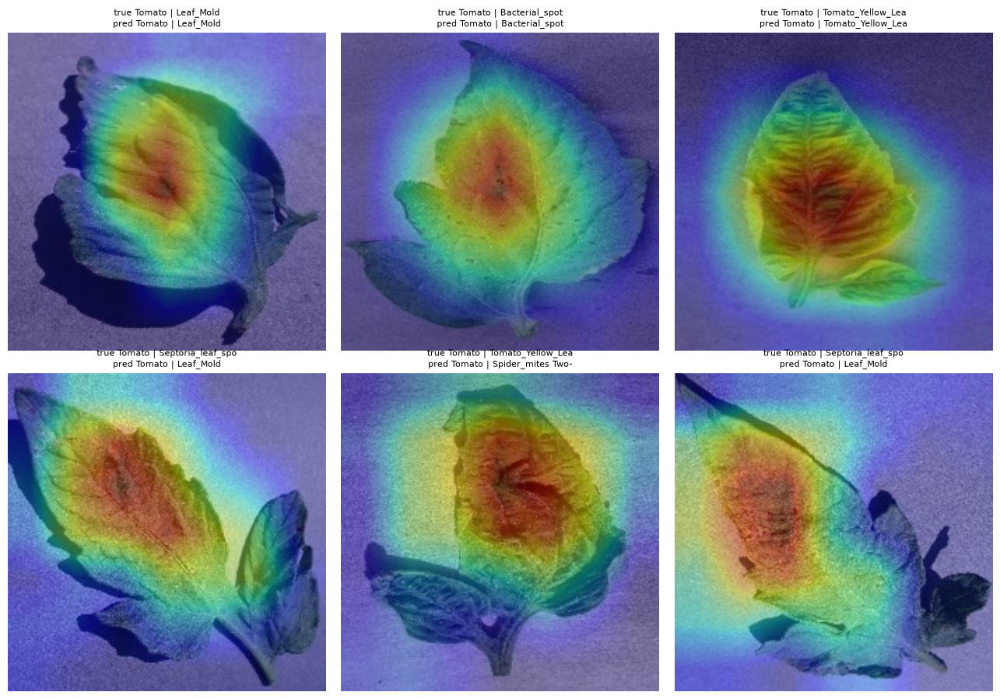

Top row = 3 correct predictions, bottom row = 3 wrong predictions
1. correct | e7391b48-0b36-41fd-81f0-35c6b5a24d0a___Crnl_L.Mold 6761.JPG
2. correct | c772de4c-5514-4b6f-b136-bf73532c7332___GCREC_Bact.Sp 3571.JPG
3. correct | 463e71e6-8b91-4e9b-ae83-0581894c3190___YLCV_NREC 0264.JPG
4. WRONG   | e0680a92-8dcf-42b4-853e-1d6a8d1d8ae2___Matt.S_CG 7510.JPG
5. WRONG   | b4807aab-c1e3-49d8-8f42-f4e429d62370___YLCV_NREC 2406.JPG
6. WRONG   | 4271d0f3-743c-4006-b9e6-fbee7ab28ec7___Matt.S_CG 7484.JPG


In [19]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handles = [layer.register_forward_hook(self._save_act),
                        layer.register_full_backward_hook(self._save_grad)]
    def remove(self):
        for h in self.handles:
            h.remove()
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls
for p in model.parameters():
    p.requires_grad = True
try:
    cam.remove()                      # avoid stacked hooks if this cell is re-run
except NameError:
    pass
cam = GradCAM(model, last_block)
rs = np.random.RandomState(1)
wrong_all = np.where(pred != y_test)[0]
right_all = np.where(pred == y_test)[0]
wrong = rs.choice(wrong_all, min(3, len(wrong_all)), replace=False).tolist()
right = rs.choice(right_all, min(3, len(right_all)), replace=False).tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y].replace("___", " | ")[:26]}\npred {classes[c].replace("___", " | ")[:26]}', fontsize=8)
plt.tight_layout(); savefig('w6_gradcam.png'); plt.show()
print('Top row = 3 correct predictions, bottom row = 3 wrong predictions')
for k, i in enumerate(right + wrong):
    print(f'{k + 1}. {"correct" if k < len(right) else "WRONG  "} | {Path(test_ds.paths[i]).name}')

In [20]:
# Extra check 1: how much of the heat sits in the outer 10% frame of the image?
# A uniform spread would give 1 - 0.8^2 = 0.36. Much higher = the model looks at edges/background.
def border_share(h, b=0.10):
    m = int(h.shape[0] * b)
    return float(1 - h[m:-m, m:-m].sum() / (h.sum() + 1e-8))
sel = np.random.RandomState(2).choice(len(test_ds), min(60, len(test_ds)), replace=False)
shares = [border_share(cam(test_ds[i][0])[0]) for i in sel]
print(f'Mean border share of Grad-CAM heat over {len(sel)} test images: {np.mean(shares):.2f} (uniform would be 0.36)')
R['border_share'] = float(np.mean(shares))
cam.remove()

# Extra check 2: background-only baseline. Can the 4 corner patches (8x8 px, mean RGB) alone predict the class?
def corner_feats(path, k=8):
    im = np.asarray(Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)
    cs = [im[:k, :k], im[:k, -k:], im[-k:, :k], im[-k:, -k:]]
    return np.concatenate([c.reshape(-1, 3).mean(0) for c in cs])
Xtr = np.stack([corner_feats(p) for p in tr_df.path]); ytr = np.array(train_ds.y)
Xva = np.stack([corner_feats(p) for p in va_df.path]); yva = np.array(val_ds.y)
rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(Xtr, ytr)
acc_bg = float((rf.predict(Xva) == yva).mean())
maj = float(np.bincount(yva, minlength=K).max() / len(yva))
print(f'Corner-pixels-only classifier, validation accuracy: {acc_bg:.3f}')
print(f'  chance (1/K) = {1 / K:.3f} | always predicting the biggest class = {maj:.3f}')
R.update(bg_acc=acc_bg, bg_chance=1 / K, bg_majority=maj)

Mean border share of Grad-CAM heat over 60 test images: 0.16 (uniform would be 0.36)
Corner-pixels-only classifier, validation accuracy: 0.438
  chance (1/K) = 0.026 | always predicting the biggest class = 0.102


### ✍️ Write it — Part 6
One line per heatmap (the three correct predictions are on the top row, the three wrong ones on the bottom row):
1. correct, true and predicted Tomato Leaf Mold: heat sits on the central leaf blade over the mottled surface, background is cold → legitimate evidence (leaf tissue).
2. correct, Tomato Bacterial spot: heat on the middle of the leaf where the spots are, not on the table → legitimate.
3. correct, Tomato Yellow Leaf Curl Virus: heat spread over the whole leaf blade and veins (yellowing, curling), the background is dark blue → legitimate.
4. WRONG, true Tomato Septoria leaf spot, predicted Leaf Mold: heat on the large central lobe only and not on the small side leaflet → it looked at leaf tissue (acceptable evidence), but the two diseases look alike and the model picked the wrong one.
5. WRONG, true Tomato Yellow Leaf Curl Virus, predicted Spider mites: heat on the upper central blade → it looked at the leaf, but at a folded, shaded part whose texture resembles mite damage.
6. WRONG, true Septoria leaf spot, predicted Leaf Mold: heat on the central-left blade, away from the dark leaflet → leaf tissue again, same confusion as no. 4.

- **Numbers that back it up:** the border share of heat is 0.16 (uniform would be 0.36), so the model does not stare at the edges. The corner-pixels-only classifier reaches 0.438 validation accuracy versus chance 0.026 and 0.102 for always predicting the biggest class, so the background alone carries a lot of class information.
- **Overall verdict:** shortcut suspected (not confirmed). Grad-CAM shows the CNN looking at the leaf, but all six heatmaps are centred, which is also where PlantVillage leaves always sit, and a classifier that sees only four 8 x 8 background corners is right 43.8% of the time, so the backgrounds are correlated with the classes and my model could be using them in part.
- **Follow-up experiment:** (1) score the trained model on the `segmented` (background removed) PlantVillage images or on the test images with the background replaced by a constant colour; a big drop in macro-F1 would confirm the shortcut; (2) mask the outer frame of the validation images and re-score; (3) test on real field photos with different backgrounds.

## Part 7: Save and document

In [21]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, MODELS / 'week6_model.pt')
size_mb = (MODELS / 'week6_model.pt').stat().st_size / 1e6
print(f'Saved models/week6_model.pt ({size_mb:.1f} MB)')
with open(PROJECT / 'week6_results.json', 'w') as f:
    json.dump(R, f, indent=2, default=str)
print('Saved week6_results.json with', len(R), 'numbers')

Saved models/week6_model.pt (44.9 MB)
Saved week6_results.json with 49 numbers


### Responsibility questions (slide 34)
1. **Who could be harmed, and how?** A farmer who is told "healthy" for a diseased crop loses harvest because the disease keeps spreading; a farmer who is told "diseased" for a healthy crop wastes money and over-sprays, which also harms the environment. A wrong disease name (for example Early blight vs Late blight vs Septoria in tomato, my weakest classes with recall 0.67 to 0.79) leads to the wrong treatment.
2. **Where was the model not validated?** Only on PlantVillage lab photos: a single leaf on a plain table, 14 crops, 38 classes, 256 x 256 px. Not on field photos, other phones and lighting, other regions and seasons, leaves with two diseases, or diseases outside the 38 classes. I trained on an 8% subsample, several test classes have only 4 to 7 images, and the corner-pixels test shows that the background leaks the label, so the 0.943 macro-F1 probably overstates field performance.
3. **What is the human role?** The model only proposes a diagnosis with a probability. A farmer or extension worker must check the leaf (and ask an expert for the tomato spot diseases) before any spraying or treatment decision. The model must never trigger treatment automatically.
4. **What evidence would change my conclusions?** Accuracy on a set of real field photos taken by farmers; a large drop of the score on segmented or background-replaced images (that would confirm the shortcut); a leakage audit on all 54k images showing sibling shots of the same leaf on both sides of the split; or a stable macro-F1 after grouping those siblings, which would make me trust the result more.

## Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
One patient contributes several near-identical X-rays (same body, same scanner, same hospital style). A random split puts some of them in train and some in test, so the model can recognise the *patient or scanner* instead of the disease. The test images are then not truly unseen and the score is inflated; splitting by patient removes this. (The same happens in my project with several photos of one leaf.)

**2. Two classes with 900 and 100 images, N / (K x n_c):**
N = 1000, K = 2.
w(900-class) = 1000 / (2 x 900) = 1000 / 1800 = **0.556**
w(100-class) = 1000 / (2 x 100) = 1000 / 200 = **5.0**
The rare class counts 9 times as much per image (5.0 / 0.556 = 9).

**3. Focal loss, gamma = 2, p_t = 0.8:**
Modulating factor = (1 − p_t)^gamma = (1 − 0.8)^2 = 0.2^2 = **0.04**, i.e. the example is down-weighted by a factor of **25** (1 / 0.04) compared with ordinary cross-entropy.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%:**
PPV = (0.90 x 0.02) / (0.90 x 0.02 + 0.05 x 0.98) = 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = **0.269 (about 27%)**. Roughly 3 out of 4 positive calls are false alarms because the disease is rare.

**5. When is macro-F1 better than weighted F1?**
Macro-F1 averages the F1 of every class equally, so a rare class that is handled badly pulls the score down. Weighted F1 weights classes by their size, so big classes dominate and a failed minority class can hide. Use macro-F1 when classes are imbalanced and every class matters (rare diseases, rare defects, my 38 leaf classes).

**6. Grad-CAM highlights a hospital label in the corner of X-rays. Next step?**
Treat it as a suspected shortcut: (1) test it, by masking or cropping the label region and re-scoring (a big drop = the model relied on it); (2) fix the data, by removing or blanking the label areas in all images (or random erasing of corners as augmentation) and retraining; (3) split by hospital as well as by patient and report performance on a hospital the model has never seen; (4) re-run Grad-CAM to confirm the model now looks at the lungs.